# Reproducing saved runs, and plotting their vertical structure

Every simulation of `archean_instellation_sweep.ipynb` has a folder in `saved_inputs/` (see `saved_inputs/README.md` for the naming and a description of each run). This notebook shows what those files are for, with no need to repeat the hours-long sweep:

1. **Rebuild a run and recover its converged state in seconds**, and check it against what was saved.
2. **Plot vertical profiles straight from the text files**, with no model at all (temperature, eddy diffusion and the mixing ratio of every gas).
3. **Restart the climate model** from its saved profile.
4. **Use a saved state as the starting point for a what-if**, here a doubled CH₄ source, which settles in a minute or two instead of the original solve.

It needs Photochem (see `environment.yml`) and `sweeplib.py` next to it (written by the sweep notebook, and also committed).

In [1]:
import csv, os, time
import numpy as np
import matplotlib.pyplot as plt
from sweeplib import reproduce_run, load_climate, read_atmosphere, read_profile, read_climate_profile, surface_summary, photochem_steady, TRACKED

saved_dir = "saved_inputs"
index = list(csv.DictReader(open(f"{saved_dir}/run_index.csv")))
print(len(index), "saved runs; first three:")
for r in index[:3]:
    print("  ", r["run_id"], "|", r["state"])

37 saved runs; first three:
   GJ876_S1400.00_CO2-1.000e-05bar | NO STEADY STATE
   GJ876_S1331.25_CO2-1.000e-05bar | NO STEADY STATE
   GJ876_S1262.50_CO2-1.659e-05bar | NO STEADY STATE


## 1. Pick two runs to compare

The Sun and GJ 876 at the same instellation (850 W/m²), where both hold 288 K in a steady state. Any run name from `saved_inputs/README.md` works.

In [2]:
def find_run(star, S):
    return next(r["run_id"] for r in index if r["star"] == star and abs(float(r["S_Wm2"]) - S) < 0.5)

runs = {"Sun": find_run("Sun", 850.0), "GJ876": find_run("GJ876", 850.0)}
runs

{'Sun': 'Sun3Ga_S0850.00_CO2-3.064e-01bar',
 'GJ876': 'GJ876_S0850.00_CO2-9.146e-02bar'}

## 2. Rebuild the runs and recover the converged state

`reproduce_run` builds the model from the saved settings, flux and atmosphere file, re-applies the saved pressure–temperature profile, and lets the photochemistry settle. Because the saved state is already converged, this takes seconds. The report compares the reproduced surface composition with the saved one.

In [3]:
models = {}
for star, rid in runs.items():
    t0 = time.time()
    pc, report = reproduce_run(rid, saved_dir=saved_dir, log=lambda m: None)
    models[star] = pc
    print(f"{star:6s} {rid}")
    print(f"        rebuilt and settled in {time.time() - t0:.1f} s (the original run took many minutes); "
          f"largest relative difference in a tracked species: {report['max_rel_diff_tracked']:.1e}")
    print("        surface mixing ratios, reproduced vs saved:  " +
          "  ".join(f"{k} {report['reproduced'][k]:.3e}/{report['saved'][k]:.3e}" for k in ("CO2", "CO", "CH4", "H2O")))

Sun    Sun3Ga_S0850.00_CO2-3.064e-01bar
        rebuilt and settled in 3.8 s (the original run took many minutes); largest relative difference in a tracked species: 7.5e-06
        surface mixing ratios, reproduced vs saved:  CO2 2.285e-01/2.285e-01  CO 1.516e-02/1.516e-02  CH4 1.978e-04/1.978e-04  H2O 6.550e-03/6.550e-03


GJ876  GJ876_S0850.00_CO2-9.146e-02bar
        rebuilt and settled in 8.8 s (the original run took many minutes); largest relative difference in a tracked species: 4.3e-03
        surface mixing ratios, reproduced vs saved:  CO2 7.970e-02/7.970e-02  CO 3.684e-02/3.684e-02  CH4 1.287e-04/1.287e-04  H2O 8.360e-03/8.360e-03


## 3. Vertical profiles from the saved files alone

`read_atmosphere` reads the saved atmosphere file into arrays (altitude, pressure, temperature, eddy diffusion and every species' mixing ratio, from the surface upward). This cell does not touch the model, so profiles of any quantity in the files can be plotted the same way.

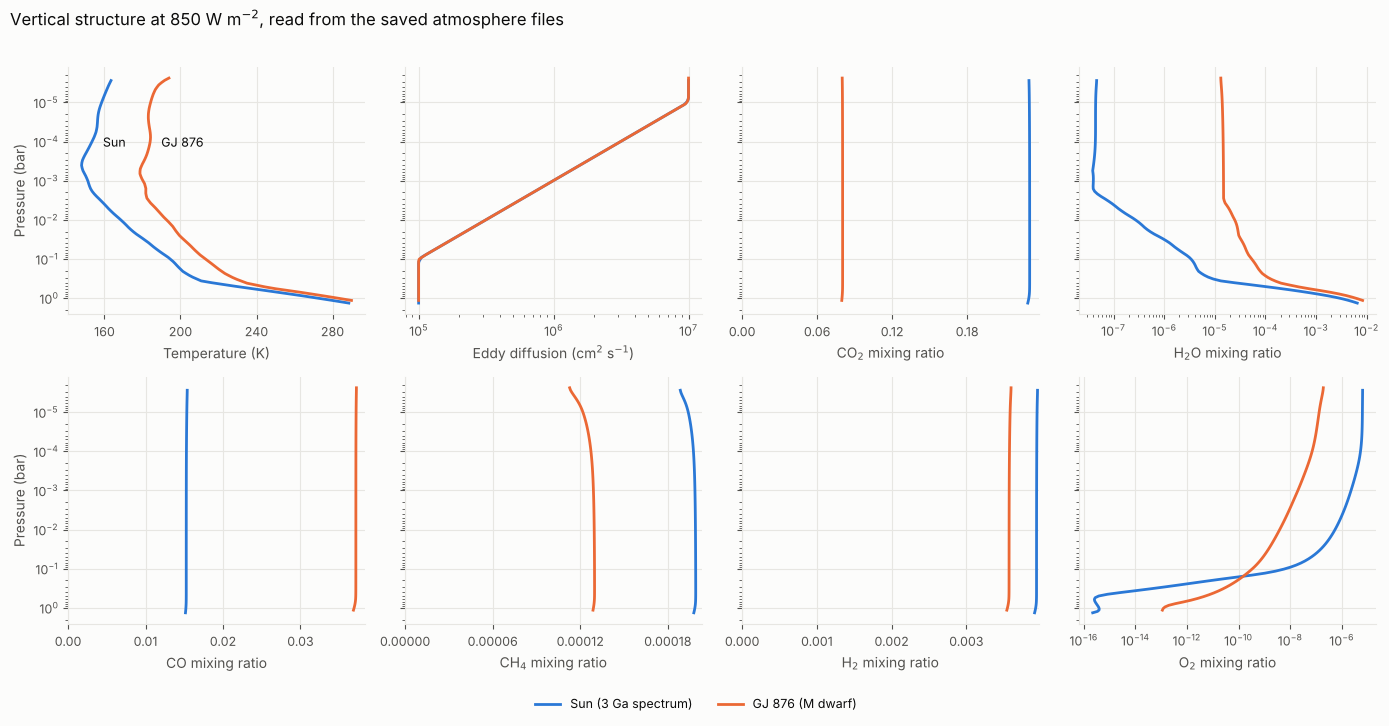

In [4]:
COLOR = {"Sun": "#2a78d6", "GJ876": "#eb6834"}          # same two colours as the other notebooks
NAME = {"Sun": "Sun (3 Ga spectrum)", "GJ876": "GJ 876 (M dwarf)"}
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "regular", "axes.titlelocation": "left", "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "lines.linewidth": 2, "legend.frameon": False, "legend.fontsize": 9})

atm = {star: read_atmosphere(f"{saved_dir}/{rid}/{rid}_photochem_atmosphere.txt") for star, rid in runs.items()}
# log axes where the profile spans decades; linear axes from zero for the well-mixed gases
panels = [("temp", "Temperature (K)", "linear"), ("eddy", "Eddy diffusion (cm$^2$ s$^{-1}$)", "log"),
          ("CO2", "CO$_2$ mixing ratio", "linear0"), ("H2O", "H$_2$O mixing ratio", "log"),
          ("CO", "CO mixing ratio", "linear0"), ("CH4", "CH$_4$ mixing ratio", "linear0"),
          ("H2", "H$_2$ mixing ratio", "linear0"), ("O2", "O$_2$ mixing ratio", "log")]
fig, axes = plt.subplots(2, 4, figsize=(14, 7.2), sharey=True)
for ax, (key, label, scale) in zip(axes.flat, panels):
    for star in runs:
        ax.plot(atm[star][key], atm[star]["press"], color=COLOR[star])
    ax.set_xscale("log" if scale == "log" else "linear"); ax.set_xlabel(label)
    if scale == "linear0": ax.set_xlim(0, None)
    ax.xaxis.set_major_locator(plt.MaxNLocator(4)) if scale != "log" else None
for ax in axes[:, 0]: ax.set_ylabel("Pressure (bar)")
axes[0, 0].set_yscale("log"); axes[0, 0].invert_yaxis()
# direct labels, at the level where the two temperature profiles are well apart
for star, ha, dx in (("Sun", "left", 8), ("GJ876", "left", 8)):
    i = int(np.argmin(np.abs(atm[star]["press"] - 1e-4)))
    axes[0, 0].annotate(NAME[star].split(" (")[0], (atm[star]["temp"][i], atm[star]["press"][i]),
                        textcoords="offset points", xytext=(dx, 0), ha=ha, va="center", color=INK, fontsize=9)
fig.suptitle("Vertical structure at 850 W m$^{-2}$, read from the saved atmosphere files", x=0.01, ha="left", fontsize=12)
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color=COLOR[s], lw=2, label=NAME[s]) for s in runs], loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.04, 1, 0.97)); plt.show()

## 4. Restart the climate model

`load_climate` rebuilds the climate model for a run and restarts the radiative–convective solve from the saved profile, so `clim.T`, `clim.P` and `clim.f_i` are available for plotting. The photochemical profile and the climate profile can differ slightly: the photochemistry ran on the profile from before its final composition was known, and the climate profile is then recomputed for the final composition (the README explains this).

In [5]:
for star, rid in runs.items():
    t0 = time.time()
    clim, ok = load_climate(rid, saved_dir=saved_dir)
    saved = read_climate_profile(f"{saved_dir}/{rid}/{rid}_climate_profile.txt")
    ph = atm[star]
    print(f"{star:6s} climate restart converged: {ok} in {time.time() - t0:.1f} s; T_surf {clim.T_surf:.3f} K "
          f"(saved {saved['T_surf_K']:.3f} K); lowest photochemical layer (a few hundred metres up) {ph['temp'][0]:.2f} K")

Sun    climate restart converged: True in 2.7 s; T_surf 287.449 K (saved 287.449 K); lowest photochemical layer (a few hundred metres up) 288.58 K


GJ876  climate restart converged: True in 4.2 s; T_surf 287.610 K (saved 287.610 K); lowest photochemical layer (a few hundred metres up) 289.98 K


## 5. A what-if from a saved state

Starting from a saved converged state makes small experiments cheap. Here the GJ 876 run is restarted and its CH₄ surface flux is doubled, with the temperature profile held fixed (so this changes the chemistry only; it does not re-solve the climate). The model settles in a minute or two, where the original solve took far longer.

In [6]:
pc = models["GJ876"]
before = surface_summary(pc)
flux_now = 3.0e10                         # the CH4 flux used in these runs (molecules cm^-2 s^-1)
pc.set_lower_bc("CH4", "flux", flux=2 * flux_now)
t0 = time.time()
reason, tn, n, wall, worst = photochem_steady(pc, TRACKED, max_wall=900)
after = surface_summary(pc)
print(f"settled ({reason}) in {time.time() - t0:.0f} s")
for k in ("CH4", "CO", "H2", "O2"):
    print(f"  {k:4s} {before[k]:.3e} -> {after[k]:.3e}  ({after[k] / before[k]:.2f}x)")

settled (composition steady over last decade) in 67 s
  CH4  1.287e-04 -> 3.039e-04  (2.36x)
  CO   3.684e-02 -> 7.174e-02  (1.95x)
  H2   3.542e-03 -> 5.743e-03  (1.62x)
  O2   1.116e-13 -> 1.300e-15  (0.01x)
